In [93]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.features.reconstruct_index import add_reconstructed_indices

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "china_cpi.csv"
)

In [94]:
cpi = load_cpi_series(DATA_PATH)
cpi = add_reconstructed_indices(cpi)

DEVELOPMENT_START = pd.Timestamp("2006-01-01")
DEVELOPMENT_END = pd.Timestamp("2014-12-01")

development = cpi.loc[
    DEVELOPMENT_START:DEVELOPMENT_END
].copy()

assert development.index.min() == DEVELOPMENT_START
assert development.index.max() == DEVELOPMENT_END
assert len(development) == 108
assert development.index.is_unique
assert development.index.is_monotonic_increasing

print(f"Development start: {development.index.min():%Y-%m}")
print(f"Development end:   {development.index.max():%Y-%m}")
print(f"Observations:      {len(development)}")

Development start: 2006-01
Development end:   2014-12
Observations:      108


In [95]:
headline = (
    development["headline_mom_published"]
    .asfreq("MS")
    .copy()
)

core = (
    development["core_mom_published"]
    .asfreq("MS")
    .copy()
)

assert headline.notna().all()
assert core.notna().all()

assert headline.index.freqstr == "MS"
assert core.index.freqstr == "MS"

print("Headline frequency:", headline.index.freqstr)
print("Core frequency:", core.index.freqstr)

pd.DataFrame(
    {
        "Headline": headline,
        "Core": core,
    }
).describe()

Headline frequency: MS
Core frequency: MS


,Headline,Core
count,108.000000,108.000000
mean,0.251852,0.086111
std,0.581085,0.173721
min,-0.900000,-0.700000
25%,-0.100000,0.000000
50%,0.200000,0.100000
75%,0.525000,0.200000
max,2.600000,0.400000


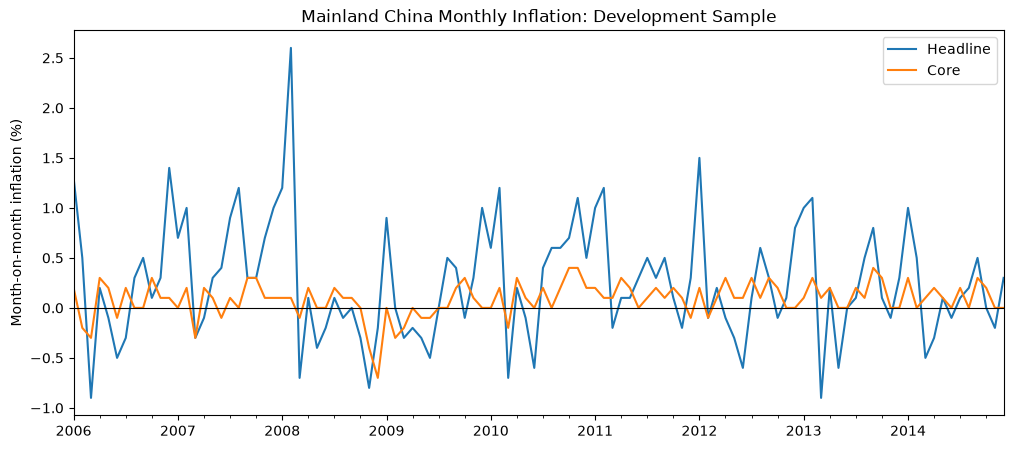

In [96]:
ax = pd.DataFrame(
    {
        "Headline": headline,
        "Core": core,
    }
).plot(
    figsize=(12, 5),
    title="Mainland China Monthly Inflation: Development Sample",
)

ax.set_xlabel("")
ax.set_ylabel("Month-on-month inflation (%)")
ax.axhline(0, color="black", linewidth=0.8)

plt.show()

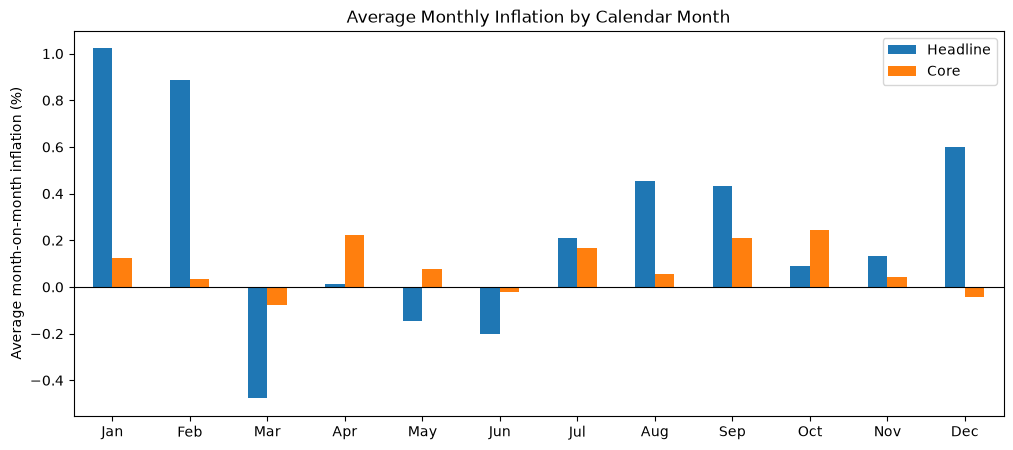

In [97]:
calendar_month_summary = pd.DataFrame(
    {
        "Headline": headline.groupby(headline.index.month).mean(),
        "Core": core.groupby(core.index.month).mean(),
    }
)

calendar_month_summary.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

calendar_month_summary

ax = calendar_month_summary.plot(
    kind="bar",
    figsize=(12, 5),
    title="Average Monthly Inflation by Calendar Month",
)

ax.set_xlabel("")
ax.set_ylabel("Average month-on-month inflation (%)")
ax.axhline(0, color="black", linewidth=0.8)

plt.xticks(rotation=0)
plt.show()

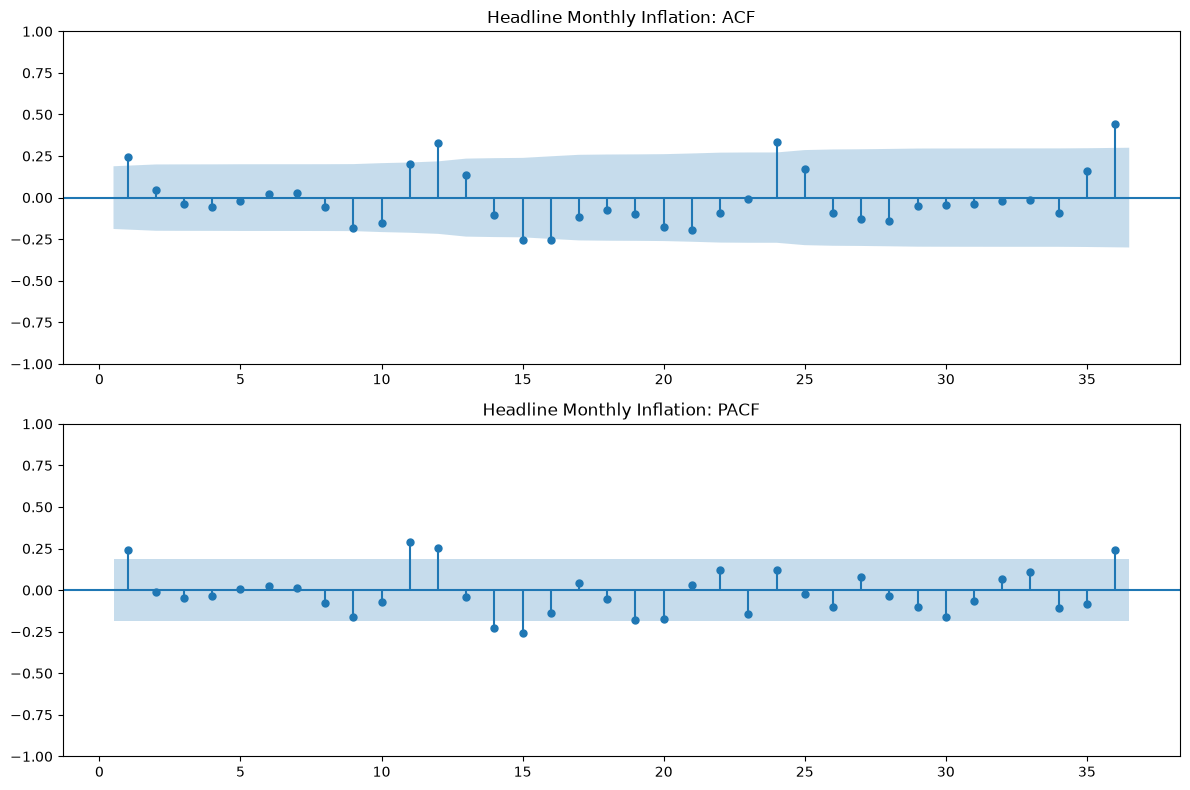

In [98]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    headline,
    lags=36,
    zero=False,
    ax=axes[0],
)
axes[0].set_title("Headline Monthly Inflation: ACF")

plot_pacf(
    headline,
    lags=36,
    zero=False,
    method="ywm",
    ax=axes[1],
)
axes[1].set_title("Headline Monthly Inflation: PACF")

plt.tight_layout()
plt.show()

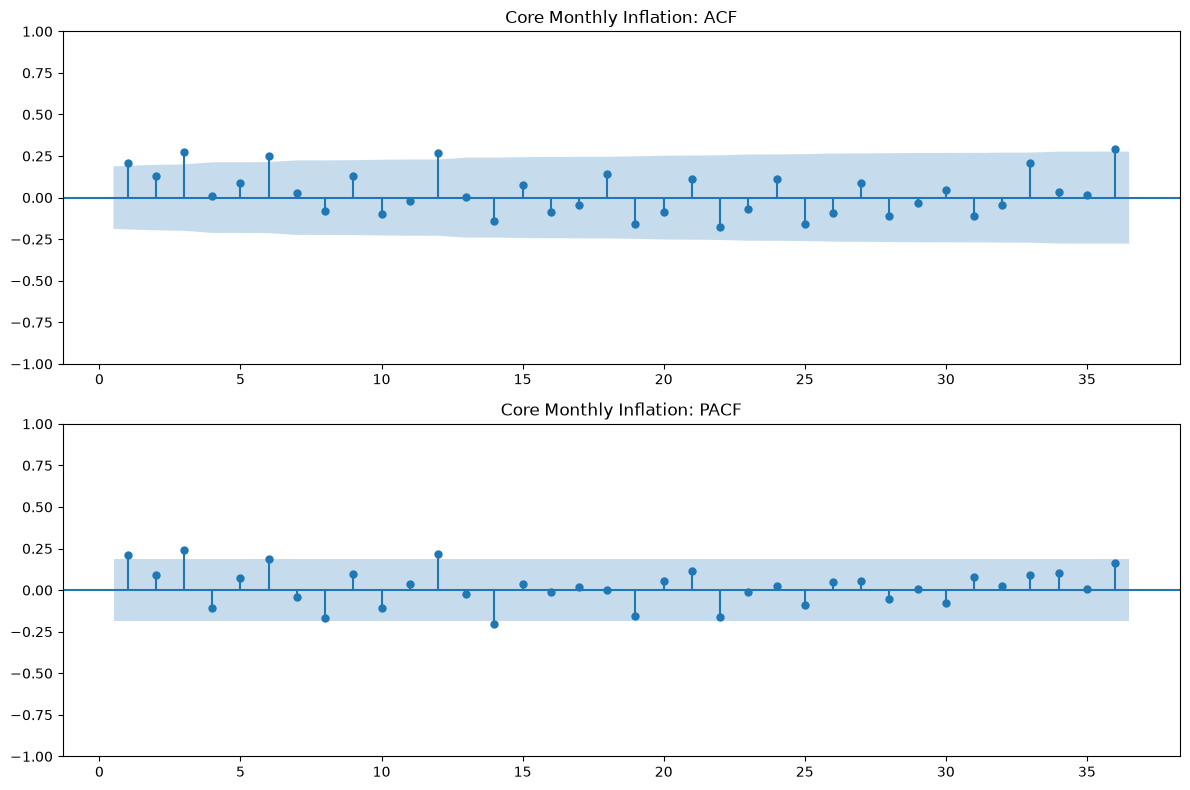

In [99]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(
    core,
    lags=36,
    zero=False,
    ax=axes[0],
)
axes[0].set_title("Core Monthly Inflation: ACF")

plot_pacf(
    core,
    lags=36,
    zero=False,
    method="ywm",
    ax=axes[1],
)
axes[1].set_title("Core Monthly Inflation: PACF")

plt.tight_layout()
plt.show()

In [100]:
def stationarity_summary(series, name):
    """Return complementary ADF and KPSS stationarity results."""
    adf_result = adfuller(
        series,
        autolag="AIC",
    )

    kpss_result = kpss(
        series,
        regression="c",
        nlags="auto",
    )

    return pd.Series(
        {
            "ADF statistic": adf_result[0],
            "ADF p-value": adf_result[1],
            "ADF lags": adf_result[2],
            "KPSS statistic": kpss_result[0],
            "KPSS p-value": kpss_result[1],
            "KPSS lags": kpss_result[2],
        },
        name=name,
    )

In [101]:
stationarity_results = pd.DataFrame(
    [
        stationarity_summary(headline, "Headline"),
        stationarity_summary(core, "Core"),
    ]
)

stationarity_results

/var/folders/nd/5qw_n51x48d4m_4651qk99sw0000gn/T/ipykernel_10309/3308837626.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(
/var/folders/nd/5qw_n51x48d4m_4651qk99sw0000gn/T/ipykernel_10309/3308837626.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(
/var/folders/nd/5qw_n51x48d4m_4651qk99sw0000gn/T/ipykernel_10309/3308837626.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after Ju

,ADF statistic,ADF p-value,ADF lags,KPSS statistic,KPSS p-value,KPSS lags
Headline,-2.290245,0.175134,13.0,0.093536,0.100000,3.0
Core,-2.398486,0.142164,13.0,0.448460,0.056267,3.0


In [102]:
headline_seasonal_difference = headline.diff(12).dropna()
core_seasonal_difference = core.diff(12).dropna()

seasonal_difference_summary = pd.DataFrame(
    {
        "Headline seasonal difference": (
            headline_seasonal_difference.describe()
        ),
        "Core seasonal difference": (
            core_seasonal_difference.describe()
        ),
    }
)

seasonal_difference_summary

,Headline seasonal difference,Core seasonal difference
count,96.000000,96.000000
mean,-0.012500,0.006250
std,0.663365,0.208661
min,-2.600000,-0.800000
25%,-0.325000,-0.100000
50%,-0.050000,0.000000
75%,0.400000,0.100000
max,1.600000,0.700000


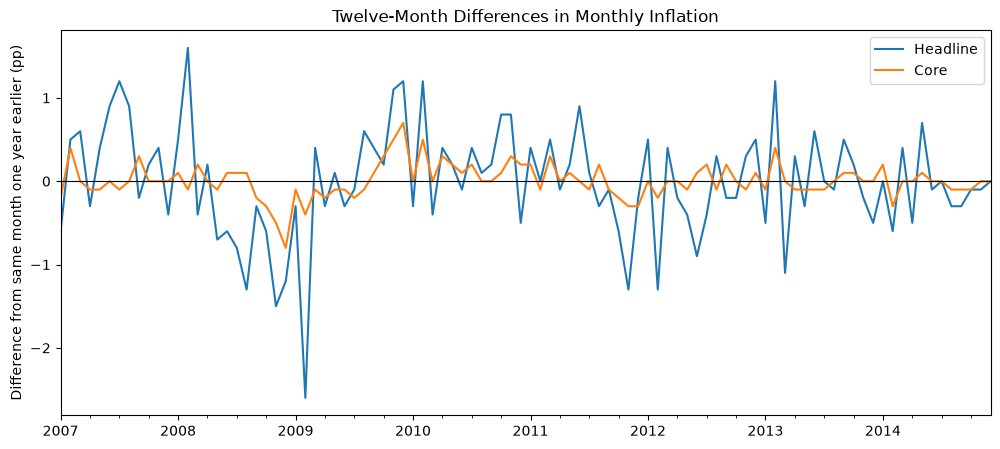

In [103]:
ax = pd.DataFrame(
    {
        "Headline": headline_seasonal_difference,
        "Core": core_seasonal_difference,
    }
).plot(
    figsize=(12, 5),
    title="Twelve-Month Differences in Monthly Inflation",
)

ax.set_xlabel("")
ax.set_ylabel("Difference from same month one year earlier (pp)")
ax.axhline(0, color="black", linewidth=0.8)

plt.show()

In [104]:
variance_comparison = pd.DataFrame(
    {
        "Original variance": [
            headline.var(),
            core.var(),
        ],
        "Seasonally differenced variance": [
            headline_seasonal_difference.var(),
            core_seasonal_difference.var(),
        ],
    },
    index=["Headline", "Core"],
)

variance_comparison

,Original variance,Seasonally differenced variance
Headline,0.337660,0.440053
Core,0.030179,0.043539


In [105]:
from itertools import product
import warnings

import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [106]:
def generate_candidate_orders():
    """Generate the predeclared low-complexity SARIMA specifications."""
    candidates = []

    for p, q, P, Q in product(
        [0, 1, 2],
        [0, 1, 2],
        [0, 1],
        [0, 1],
    ):
        total_dynamic_order = p + q + P + Q

        if total_dynamic_order <= 4:
            candidates.append(
                {
                    "order": (p, 0, q),
                    "seasonal_order": (P, 0, Q, 12),
                    "dynamic_order": total_dynamic_order,
                }
            )

    return candidates


candidate_orders = generate_candidate_orders()

print(f"Number of candidate specifications: {len(candidate_orders)}")

candidate_orders[:5]

Number of candidate specifications: 31


[{'order': (0, 0, 0), 'seasonal_order': (0, 0, 0, 12), 'dynamic_order': 0},
 {'order': (0, 0, 0), 'seasonal_order': (0, 0, 1, 12), 'dynamic_order': 1},
 {'order': (0, 0, 0), 'seasonal_order': (1, 0, 0, 12), 'dynamic_order': 1},
 {'order': (0, 0, 0), 'seasonal_order': (1, 0, 1, 12), 'dynamic_order': 2},
 {'order': (0, 0, 1), 'seasonal_order': (0, 0, 0, 12), 'dynamic_order': 1}]

In [107]:
def calculate_aicc(aic, nobs, number_of_parameters):
    """Calculate the small-sample corrected Akaike information criterion."""
    denominator = nobs - number_of_parameters - 1

    if denominator <= 0:
        return np.nan

    correction = (
        2
        * number_of_parameters
        * (number_of_parameters + 1)
        / denominator
    )

    return aic + correction

In [108]:
def fit_sarima_candidates(series, target_name, candidates):
    """Fit and record every predeclared SARIMA candidate."""
    result_rows = []
    fitted_models = {}

    for candidate in candidates:
        order = candidate["order"]
        seasonal_order = candidate["seasonal_order"]

        warning_messages = []

        try:
            with warnings.catch_warnings(record=True) as captured_warnings:
                warnings.simplefilter("always")

                model = SARIMAX(
                    series,
                    order=order,
                    seasonal_order=seasonal_order,
                    trend="c",
                    enforce_stationarity=True,
                    enforce_invertibility=True,
                )

                fitted = model.fit(
                    disp=False,
                    maxiter=500,
                )

                warning_messages = [
                    str(item.message)
                    for item in captured_warnings
                ]

            converged = bool(
                fitted.mle_retvals.get("converged", False)
            )

            finite_parameters = bool(
                np.isfinite(fitted.params).all()
            )

            finite_likelihood = bool(
                np.isfinite(fitted.llf)
            )

            number_of_parameters = len(fitted.params)
            nobs = int(fitted.nobs_effective)

            aicc = calculate_aicc(
                aic=fitted.aic,
                nobs=nobs,
                number_of_parameters=number_of_parameters,
            )

            valid_fit = (
                converged
                and finite_parameters
                and finite_likelihood
                and np.isfinite(aicc)
            )

            model_key = (
                order,
                seasonal_order,
            )

            fitted_models[model_key] = fitted

            result_rows.append(
                {
                    "target": target_name,
                    "order": order,
                    "seasonal_order": seasonal_order,
                    "dynamic_order": candidate[
                        "dynamic_order"
                    ],
                    "parameters": number_of_parameters,
                    "nobs": nobs,
                    "converged": converged,
                    "finite_parameters": finite_parameters,
                    "valid_fit": valid_fit,
                    "log_likelihood": fitted.llf,
                    "aic": fitted.aic,
                    "aicc": aicc,
                    "bic": fitted.bic,
                    "warning_count": len(warning_messages),
                    "warnings": " | ".join(warning_messages),
                }
            )

        except Exception as error:
            result_rows.append(
                {
                    "target": target_name,
                    "order": order,
                    "seasonal_order": seasonal_order,
                    "dynamic_order": candidate[
                        "dynamic_order"
                    ],
                    "parameters": np.nan,
                    "nobs": len(series),
                    "converged": False,
                    "finite_parameters": False,
                    "valid_fit": False,
                    "log_likelihood": np.nan,
                    "aic": np.nan,
                    "aicc": np.nan,
                    "bic": np.nan,
                    "warning_count": np.nan,
                    "warnings": f"{type(error).__name__}: {error}",
                }
            )

    results = pd.DataFrame(result_rows)

    valid_mask = results["valid_fit"]

    if valid_mask.any():
        results.loc[valid_mask, "delta_aicc"] = (
            results.loc[valid_mask, "aicc"]
            - results.loc[valid_mask, "aicc"].min()
        )

        results.loc[valid_mask, "delta_bic"] = (
            results.loc[valid_mask, "bic"]
            - results.loc[valid_mask, "bic"].min()
        )

    results = results.sort_values(
        by=[
            "valid_fit",
            "aicc",
            "bic",
            "dynamic_order",
        ],
        ascending=[
            False,
            True,
            True,
            True,
        ],
        na_position="last",
    ).reset_index(drop=True)

    return results, fitted_models

In [109]:
headline_search, headline_fitted_models = fit_sarima_candidates(
    series=headline,
    target_name="Headline",
    candidates=candidate_orders,
)

headline_search.head(10)

,target,order,seasonal_order,dynamic_order,parameters,nobs,converged,finite_parameters,valid_fit,log_likelihood,aic,aicc,bic,warning_count,warnings,delta_aicc,delta_bic
0,Headline,"(1, 0, 1)","(1, 0, 1, 12)",4,6,108,True,True,True,-67.278904,146.557809,147.389492,162.650596,0,,0.000000,0.866179
1,Headline,"(2, 0, 0)","(1, 0, 1, 12)",4,6,108,True,True,True,-67.444388,146.888776,147.720459,162.981563,0,,0.330967,1.197146
2,Headline,"(0, 0, 2)","(1, 0, 1, 12)",4,6,108,True,True,True,-68.565259,149.130517,149.962200,165.223304,0,,2.572708,3.438887
3,Headline,"(1, 0, 0)","(1, 0, 1, 12)",3,5,108,True,True,True,-70.154205,150.308411,150.896646,163.719067,0,,3.507154,1.934650
4,Headline,"(0, 0, 0)","(1, 0, 1, 12)",2,4,108,True,True,True,-71.527946,151.055892,151.444242,161.784417,0,,4.054750,0.000000
5,Headline,"(0, 0, 1)","(1, 0, 1, 12)",3,5,108,True,True,True,-70.566177,151.132353,151.720589,164.543009,0,,4.331097,2.758592
6,Headline,"(1, 0, 0)","(1, 0, 0, 12)",2,4,108,True,True,True,-85.465487,178.930975,179.319325,189.659500,0,,31.929833,27.875083
7,Headline,"(1, 0, 1)","(1, 0, 0, 12)",3,5,108,True,True,True,-84.368773,178.737547,179.325782,192.148203,0,,31.936290,30.363786
8,Headline,"(2, 0, 0)","(1, 0, 0, 12)",3,5,108,True,True,True,-84.401285,178.802569,179.390804,192.213225,0,,32.001312,30.428808
9,Headline,"(2, 0, 2)","(0, 0, 0, 12)",4,6,108,True,True,True,-83.306620,178.613240,179.444923,194.706028,0,,32.055431,32.921610


In [110]:
headline_fit_summary = pd.Series(
    {
        "Candidates": len(headline_search),
        "Valid fits": headline_search["valid_fit"].sum(),
        "Failed or invalid fits": (
            (~headline_search["valid_fit"]).sum()
        ),
        "Converged fits": headline_search["converged"].sum(),
        "Fits with warnings": (
            headline_search["warning_count"].fillna(0) > 0
        ).sum(),
    },
    name="Headline",
)

headline_fit_summary

Candidates                31
Valid fits                31
Failed or invalid fits     0
Converged fits            31
Fits with warnings         0
Name: Headline, dtype: int64

In [111]:
headline_leaders = headline_search.loc[
    headline_search["valid_fit"],
    [
        "order",
        "seasonal_order",
        "dynamic_order",
        "parameters",
        "aicc",
        "delta_aicc",
        "bic",
        "delta_bic",
        "warning_count",
    ],
].head(12)

headline_leaders

,order,seasonal_order,dynamic_order,parameters,aicc,delta_aicc,bic,delta_bic,warning_count
0,"(1, 0, 1)","(1, 0, 1, 12)",4,6,147.389492,0.000000,162.650596,0.866179,0
1,"(2, 0, 0)","(1, 0, 1, 12)",4,6,147.720459,0.330967,162.981563,1.197146,0
2,"(0, 0, 2)","(1, 0, 1, 12)",4,6,149.962200,2.572708,165.223304,3.438887,0
3,"(1, 0, 0)","(1, 0, 1, 12)",3,5,150.896646,3.507154,163.719067,1.934650,0
4,"(0, 0, 0)","(1, 0, 1, 12)",2,4,151.444242,4.054750,161.784417,0.000000,0
5,"(0, 0, 1)","(1, 0, 1, 12)",3,5,151.720589,4.331097,164.543009,2.758592,0
6,"(1, 0, 0)","(1, 0, 0, 12)",2,4,179.319325,31.929833,189.659500,27.875083,0
7,"(1, 0, 1)","(1, 0, 0, 12)",3,5,179.325782,31.936290,192.148203,30.363786,0
8,"(2, 0, 0)","(1, 0, 0, 12)",3,5,179.390804,32.001312,192.213225,30.428808,0
9,"(2, 0, 2)","(0, 0, 0, 12)",4,6,179.444923,32.055431,194.706028,32.921610,0


In [112]:
core_search, core_fitted_models = fit_sarima_candidates(
    series=core,
    target_name="Core",
    candidates=candidate_orders,
)

core_search.head(10)

,target,order,seasonal_order,dynamic_order,parameters,nobs,converged,finite_parameters,valid_fit,log_likelihood,aic,aicc,bic,warning_count,warnings,delta_aicc,delta_bic
0,Core,"(2, 0, 0)","(1, 0, 1, 12)",4,6,108,True,True,True,54.690503,-97.381005,-96.549322,-81.288218,0,,0.000000,0.000000
1,Core,"(1, 0, 1)","(1, 0, 1, 12)",4,6,108,True,True,True,54.639963,-97.279927,-96.448244,-81.187139,0,,0.101079,0.101079
2,Core,"(1, 0, 0)","(1, 0, 1, 12)",3,5,108,True,True,True,51.672830,-93.345659,-92.757424,-79.935003,0,,3.791898,1.353215
3,Core,"(0, 0, 2)","(1, 0, 1, 12)",4,6,108,True,True,True,52.587223,-93.174445,-92.342762,-77.081658,0,,4.206560,4.206560
4,Core,"(0, 0, 1)","(1, 0, 1, 12)",3,5,108,True,True,True,49.459768,-88.919535,-88.331300,-75.508879,0,,8.218022,5.779339
5,Core,"(1, 0, 1)","(1, 0, 0, 12)",3,5,108,True,True,True,47.197766,-84.395531,-83.807296,-70.984875,0,,12.742026,10.303343
6,Core,"(2, 0, 0)","(1, 0, 0, 12)",3,5,108,True,True,True,46.905267,-83.810535,-83.222300,-70.399879,0,,13.327022,10.888339
7,Core,"(1, 0, 2)","(1, 0, 0, 12)",4,6,108,True,True,True,47.687403,-83.374806,-82.543123,-67.282019,0,,14.006199,14.006199
8,Core,"(2, 0, 1)","(1, 0, 0, 12)",4,6,108,True,True,True,47.586023,-83.172046,-82.340363,-67.079258,2,Non-stationary starting autoregressive paramet...,14.208960,14.208960
9,Core,"(1, 0, 1)","(0, 0, 1, 12)",3,5,108,True,True,True,46.345194,-82.690388,-82.102153,-69.279732,0,,14.447169,12.008486


In [113]:
core_fit_summary = pd.Series(
    {
        "Candidates": len(core_search),
        "Valid fits": core_search["valid_fit"].sum(),
        "Failed or invalid fits": (
            (~core_search["valid_fit"]).sum()
        ),
        "Converged fits": core_search["converged"].sum(),
        "Fits with warnings": (
            core_search["warning_count"].fillna(0) > 0
        ).sum(),
    },
    name="Core",
)

core_fit_summary

Candidates                31
Valid fits                31
Failed or invalid fits     0
Converged fits            31
Fits with warnings         3
Name: Core, dtype: int64

In [114]:
core_leaders = core_search.loc[
    core_search["valid_fit"],
    [
        "order",
        "seasonal_order",
        "dynamic_order",
        "parameters",
        "aicc",
        "delta_aicc",
        "bic",
        "delta_bic",
        "warning_count",
    ],
].head(12)

core_leaders

,order,seasonal_order,dynamic_order,parameters,aicc,delta_aicc,bic,delta_bic,warning_count
0,"(2, 0, 0)","(1, 0, 1, 12)",4,6,-96.549322,0.000000,-81.288218,0.000000,0
1,"(1, 0, 1)","(1, 0, 1, 12)",4,6,-96.448244,0.101079,-81.187139,0.101079,0
2,"(1, 0, 0)","(1, 0, 1, 12)",3,5,-92.757424,3.791898,-79.935003,1.353215,0
3,"(0, 0, 2)","(1, 0, 1, 12)",4,6,-92.342762,4.206560,-77.081658,4.206560,0
4,"(0, 0, 1)","(1, 0, 1, 12)",3,5,-88.331300,8.218022,-75.508879,5.779339,0
5,"(1, 0, 1)","(1, 0, 0, 12)",3,5,-83.807296,12.742026,-70.984875,10.303343,0
6,"(2, 0, 0)","(1, 0, 0, 12)",3,5,-83.222300,13.327022,-70.399879,10.888339,0
7,"(1, 0, 2)","(1, 0, 0, 12)",4,6,-82.543123,14.006199,-67.282019,14.006199,0
8,"(2, 0, 1)","(1, 0, 0, 12)",4,6,-82.340363,14.208960,-67.079258,14.208960,2
9,"(1, 0, 1)","(0, 0, 1, 12)",3,5,-82.102153,14.447169,-69.279732,12.008486,0


In [115]:
headline_search.loc[
    ~headline_search["valid_fit"],
    [
        "order",
        "seasonal_order",
        "converged",
        "warning_count",
        "warnings",
    ],
]

,order,seasonal_order,converged,warning_count,warnings


In [116]:
core_search.loc[
    ~core_search["valid_fit"],
    [
        "order",
        "seasonal_order",
        "converged",
        "warning_count",
        "warnings",
    ],
]

,order,seasonal_order,converged,warning_count,warnings


In [117]:
headline_search.loc[
    headline_search["valid_fit"]
    & (headline_search["warning_count"].fillna(0) > 0),
    [
        "order",
        "seasonal_order",
        "warning_count",
        "warnings",
    ],
].head(10)

,order,seasonal_order,warning_count,warnings


In [118]:
core_search.loc[
    core_search["valid_fit"]
    & (core_search["warning_count"].fillna(0) > 0),
    [
        "order",
        "seasonal_order",
        "warning_count",
        "warnings",
    ],
].head(10)

,order,seasonal_order,warning_count,warnings
8,"(2, 0, 1)","(1, 0, 0, 12)",2,Non-stationary starting autoregressive paramet...
14,"(2, 0, 1)","(0, 0, 1, 12)",2,Non-stationary starting autoregressive paramet...
27,"(2, 0, 1)","(0, 0, 0, 12)",2,Non-stationary starting autoregressive paramet...


In [119]:
def model_parameter_table(fitted_model):
    """Return estimates, uncertainty, and confidence intervals."""
    confidence_intervals = fitted_model.conf_int()

    return pd.DataFrame(
        {
            "estimate": fitted_model.params,
            "standard_error": fitted_model.bse,
            "z_statistic": fitted_model.tvalues,
            "p_value": fitted_model.pvalues,
            "ci_lower": confidence_intervals.iloc[:, 0],
            "ci_upper": confidence_intervals.iloc[:, 1],
        }
    )

In [120]:
headline_best_key = (
    (1, 0, 1),
    (1, 0, 1, 12),
)

headline_best = headline_fitted_models[headline_best_key]

model_parameter_table(headline_best)

,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000055,0.001233,0.044332,9.646397e-01,-0.002363,0.002472
ar.L1,0.847050,0.160398,5.280910,1.285438e-07,0.532675,1.161425
ma.L1,-0.670401,0.201201,-3.332006,8.622246e-04,-1.064747,-0.276056
ar.S.L12,0.998537,0.033322,29.966080,2.716394e-197,0.933226,1.063847
ma.S.L12,-0.945359,0.612694,-1.542953,1.228422e-01,-2.146218,0.255500
sigma2,0.164205,0.085983,1.909735,5.616736e-02,-0.004319,0.332730


In [121]:
print("AR roots:")
print(headline_best.arroots)

print("\nMA roots:")
print(headline_best.maroots)

print("\nMinimum AR-root modulus:")
print(abs(headline_best.arroots).min())

print("\nMinimum MA-root modulus:")
print(abs(headline_best.maroots).min())

AR roots:
[-1.00012205e+00-0.j         -8.66131103e-01-0.50006103j
 -8.66131103e-01+0.50006103j -5.00061025e-01-0.8661311j
 -5.00061025e-01+0.8661311j   1.86004815e-16-1.00012205j
  1.86004815e-16+1.00012205j  5.00061025e-01-0.8661311j
  5.00061025e-01+0.8661311j   8.66131103e-01-0.50006103j
  8.66131103e-01+0.50006103j  1.00012205e+00-0.j
  1.18056795e+00-0.j        ]

MA roots:
[-1.00469355e+00-0.j         -8.70090139e-01-0.50234678j
 -8.70090139e-01+0.50234678j -5.02346776e-01-0.87009014j
 -5.02346776e-01+0.87009014j -5.34028792e-17-1.00469355j
 -5.34028792e-17+1.00469355j  5.02346776e-01-0.87009014j
  5.02346776e-01+0.87009014j  8.70090139e-01-0.50234678j
  8.70090139e-01+0.50234678j  1.00469355e+00-0.j
  1.49164382e+00-0.j        ]

Minimum AR-root modulus:
1.000122050736143

Minimum MA-root modulus:
1.004693551770064


In [122]:
core_best_key = (
    (2, 0, 0),
    (1, 0, 1, 12),
)

core_best = core_fitted_models[core_best_key]

model_parameter_table(core_best)

,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000483,0.002210,0.218670,8.269074e-01,-0.003848,0.004815
ar.L1,0.266733,0.084168,3.169066,1.529299e-03,0.101767,0.431698
ar.L2,0.239665,0.105109,2.280145,2.259912e-02,0.033654,0.445676
ar.S.L12,0.988620,0.051478,19.204769,3.376252e-82,0.887726,1.089515
ma.S.L12,-0.876777,0.280170,-3.129448,1.751348e-03,-1.425899,-0.327654
sigma2,0.018608,0.003952,4.708022,2.501316e-06,0.010862,0.026355


In [123]:
print("AR roots:")
print(core_best.arroots)

print("\nMA roots:")
print(core_best.maroots)

print("\nMinimum AR-root modulus:")
print(abs(core_best.arroots).min())

print("\nMinimum MA-root modulus:")
print(abs(core_best.maroots).min())

AR roots:
[-1.00095419e+00-0.j         -8.66851757e-01-0.5004771j
 -8.66851757e-01+0.5004771j  -5.00477095e-01-0.86685176j
 -5.00477095e-01+0.86685176j  9.84361534e-17-1.00095419j
  9.84361534e-17+1.00095419j  5.00477095e-01-0.86685176j
  5.00477095e-01+0.86685176j  8.66851757e-01-0.5004771j
  8.66851757e-01+0.5004771j   1.00095419e+00-0.j
  1.56063941e+00-0.j         -2.67358044e+00-0.j        ]

MA roots:
[-1.01101883e+00-0.j         -8.75567991e-01-0.50550942j
 -8.75567991e-01+0.50550942j -5.05509415e-01-0.87556799j
 -5.05509415e-01+0.87556799j -1.40625579e-16-1.01101883j
 -1.40625579e-16+1.01101883j  5.05509415e-01-0.87556799j
  5.05509415e-01+0.87556799j  1.01101883e+00-0.j
  8.75567991e-01-0.50550942j  8.75567991e-01+0.50550942j]

Minimum AR-root modulus:
1.0009541900455587

Minimum MA-root modulus:
1.011018830412173


In [124]:
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox


headline_shortlist = [
    ((1, 0, 1), (1, 0, 1, 12)),
    ((2, 0, 0), (1, 0, 1, 12)),
    ((0, 0, 0), (1, 0, 1, 12)),
    ((1, 0, 0), (1, 0, 1, 12)),
]

core_shortlist = [
    ((2, 0, 0), (1, 0, 1, 12)),
    ((1, 0, 1), (1, 0, 1, 12)),
    ((1, 0, 0), (1, 0, 1, 12)),
    ((0, 0, 2), (1, 0, 1, 12)),
]


def residual_diagnostics(
    fitted_model,
    order,
    seasonal_order,
):
    """Calculate residual and root diagnostics for one SARIMA fit."""
    residuals = pd.Series(fitted_model.resid).dropna()

    burn_in = max(
        int(getattr(fitted_model, "loglikelihood_burn", 0)),
        12,
    )

    residuals = residuals.iloc[burn_in:]

    p, _, q = order
    P, _, Q, _ = seasonal_order

    model_df = p + q + P + Q

    ljung_box = acorr_ljungbox(
        residuals,
        lags=[12, 24],
        model_df=model_df,
        return_df=True,
    )

    ar_roots = np.asarray(fitted_model.arroots)
    ma_roots = np.asarray(fitted_model.maroots)

    minimum_ar_root = (
        np.min(np.abs(ar_roots))
        if ar_roots.size > 0
        else np.nan
    )

    minimum_ma_root = (
        np.min(np.abs(ma_roots))
        if ma_roots.size > 0
        else np.nan
    )

    return {
        "residual_count": len(residuals),
        "residual_mean": residuals.mean(),
        "residual_std": residuals.std(ddof=1),
        "ljung_box_p_12": ljung_box.loc[12, "lb_pvalue"],
        "ljung_box_p_24": ljung_box.loc[24, "lb_pvalue"],
        "minimum_ar_root_modulus": minimum_ar_root,
        "minimum_ma_root_modulus": minimum_ma_root,
    }


print("Headline shortlist:", len(headline_shortlist))
print("Core shortlist:", len(core_shortlist))
print(
    "Diagnostic function available:",
    callable(residual_diagnostics),
)

Headline shortlist: 4
Core shortlist: 4
Diagnostic function available: True


In [125]:
for key in headline_shortlist:
    assert key in headline_fitted_models, (
        f"Missing headline model: {key}"
    )

for key in core_shortlist:
    assert key in core_fitted_models, (
        f"Missing core model: {key}"
    )

print("All shortlisted fitted models are available.")

All shortlisted fitted models are available.


In [126]:
headline_diagnostic_rows = []

for order, seasonal_order in headline_shortlist:
    fitted = headline_fitted_models[
        (order, seasonal_order)
    ]

    diagnostic = residual_diagnostics(
        fitted_model=fitted,
        order=order,
        seasonal_order=seasonal_order,
    )

    diagnostic["order"] = order
    diagnostic["seasonal_order"] = seasonal_order

    headline_diagnostic_rows.append(diagnostic)

headline_diagnostics = pd.DataFrame(
    headline_diagnostic_rows
)

headline_diagnostics = headline_diagnostics.set_index(
    ["order", "seasonal_order"]
)

headline_diagnostics

,,residual_count,residual_mean,residual_std,ljung_box_p_12,ljung_box_p_24,minimum_ar_root_modulus,minimum_ma_root_modulus
order,seasonal_order,,,,,,,
"(1, 0, 1)","(1, 0, 1, 12)",96,-0.016428,0.438040,0.003299,2.952752e-02,1.000122,1.004694
"(2, 0, 0)","(1, 0, 1, 12)",96,-0.017978,0.439359,0.004185,1.082349e-02,1.000044,1.002876
"(0, 0, 0)","(1, 0, 1, 12)",96,-0.020715,0.461588,0.000030,4.679028e-07,1.000037,1.002382
"(1, 0, 0)","(1, 0, 1, 12)",96,-0.019559,0.455817,0.000397,3.558031e-04,1.000061,1.003120


In [127]:
core_diagnostic_rows = []

for order, seasonal_order in core_shortlist:
    fitted = core_fitted_models[
        (order, seasonal_order)
    ]

    diagnostic = residual_diagnostics(
        fitted_model=fitted,
        order=order,
        seasonal_order=seasonal_order,
    )

    diagnostic["order"] = order
    diagnostic["seasonal_order"] = seasonal_order

    core_diagnostic_rows.append(diagnostic)

core_diagnostics = pd.DataFrame(
    core_diagnostic_rows
)

core_diagnostics = core_diagnostics.set_index(
    ["order", "seasonal_order"]
)

core_diagnostics

,,residual_count,residual_mean,residual_std,ljung_box_p_12,ljung_box_p_24,minimum_ar_root_modulus,minimum_ma_root_modulus
order,seasonal_order,,,,,,,
"(2, 0, 0)","(1, 0, 1, 12)",96,0.009330,0.139060,0.473439,0.130903,1.000954,1.011019
"(1, 0, 1)","(1, 0, 1, 12)",96,0.005831,0.140725,0.273833,0.083476,1.002539,1.017211
"(1, 0, 0)","(1, 0, 1, 12)",96,0.012257,0.145624,0.074582,0.019220,1.000538,1.007569
"(0, 0, 2)","(1, 0, 1, 12)",96,0.012476,0.141922,0.102748,0.056300,1.001279,1.013068


In [128]:
def model_parameter_table(fitted_model):
    """Return parameter estimates and uncertainty measures."""
    confidence_intervals = fitted_model.conf_int()

    return pd.DataFrame(
        {
            "estimate": fitted_model.params,
            "standard_error": fitted_model.bse,
            "z_statistic": fitted_model.tvalues,
            "p_value": fitted_model.pvalues,
            "ci_lower": confidence_intervals.iloc[:, 0],
            "ci_upper": confidence_intervals.iloc[:, 1],
        }
    )

In [129]:
for order, seasonal_order in headline_shortlist:
    print(
        "\nHeadline:",
        f"SARIMA{order}x{seasonal_order}",
    )

    display(
        model_parameter_table(
            headline_fitted_models[
                (order, seasonal_order)
            ]
        )
    )


Headline: SARIMA(1, 0, 1)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000055,0.001233,0.044332,9.646397e-01,-0.002363,0.002472
ar.L1,0.847050,0.160398,5.280910,1.285438e-07,0.532675,1.161425
ma.L1,-0.670401,0.201201,-3.332006,8.622246e-04,-1.064747,-0.276056
ar.S.L12,0.998537,0.033322,29.966080,2.716394e-197,0.933226,1.063847
ma.S.L12,-0.945359,0.612694,-1.542953,1.228422e-01,-2.146218,0.255500
sigma2,0.164205,0.085983,1.909735,5.616736e-02,-0.004319,0.332730



Headline: SARIMA(2, 0, 0)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000077,0.004445,0.017258,9.862307e-01,-0.008634,0.008788
ar.L1,0.118580,0.084471,1.403797,1.603792e-01,-0.046980,0.284139
ar.L2,0.237932,0.120857,1.968714,4.898598e-02,0.001057,0.474807
ar.S.L12,0.999476,0.030324,32.960299,3.011940e-238,0.940043,1.058910
ma.S.L12,-0.966125,0.968763,-0.997277,3.186302e-01,-2.864865,0.932616
sigma2,0.159822,0.143276,1.115485,2.646427e-01,-0.120994,0.440638



Headline: SARIMA(0, 0, 0)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000111,0.009624,0.011528,9.908023e-01,-0.018752,0.018974
ar.S.L12,0.999553,0.038792,25.767225,2.066958e-146,0.923523,1.075583
ma.S.L12,-0.971856,1.206746,-0.805353,4.206161e-01,-3.337034,1.393322
sigma2,0.174636,0.196780,0.887468,3.748269e-01,-0.211046,0.560317



Headline: SARIMA(1, 0, 0)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000149,0.007308,0.020418,9.837099e-01,-0.014174,0.014473
ar.L1,0.158518,0.080635,1.965865,4.931418e-02,0.000476,0.316560
ar.S.L12,0.999265,0.036034,27.731103,2.945304e-169,0.928640,1.069891
ma.S.L12,-0.963307,0.887759,-1.085100,2.778774e-01,-2.703283,0.776668
sigma2,0.166750,0.134855,1.236519,2.162657e-01,-0.097560,0.431060


In [130]:
for order, seasonal_order in core_shortlist:
    print(
        "\nCore:",
        f"SARIMA{order}x{seasonal_order}",
    )

    display(
        model_parameter_table(
            core_fitted_models[
                (order, seasonal_order)
            ]
        )
    )


Core: SARIMA(2, 0, 0)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000483,0.002210,0.218670,8.269074e-01,-0.003848,0.004815
ar.L1,0.266733,0.084168,3.169066,1.529299e-03,0.101767,0.431698
ar.L2,0.239665,0.105109,2.280145,2.259912e-02,0.033654,0.445676
ar.S.L12,0.988620,0.051478,19.204769,3.376252e-82,0.887726,1.089515
ma.S.L12,-0.876777,0.280170,-3.129448,1.751348e-03,-1.425899,-0.327654
sigma2,0.018608,0.003952,4.708022,2.501316e-06,0.010862,0.026355



Core: SARIMA(1, 0, 1)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000316,0.000978,0.322854,7.468062e-01,-0.001601,0.002232
ar.L1,0.873892,0.130061,6.719111,1.828367e-11,0.618978,1.128806
ma.L1,-0.634921,0.163979,-3.871969,1.079598e-04,-0.956314,-0.313528
ar.S.L12,0.970033,0.078581,12.344398,5.222334e-35,0.816017,1.124048
ma.S.L12,-0.814828,0.255115,-3.193967,1.403323e-03,-1.314843,-0.314812
sigma2,0.019459,0.003088,6.301123,2.954975e-10,0.013406,0.025511



Core: SARIMA(1, 0, 0)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.000352,0.002670,0.132003,8.949823e-01,-0.004881,0.005586
ar.L1,0.353421,0.081761,4.322584,1.542120e-05,0.193171,0.513670
ar.S.L12,0.993568,0.048745,20.382933,2.370173e-92,0.898029,1.089107
ma.S.L12,-0.913489,0.328907,-2.777343,5.480531e-03,-1.558136,-0.268842
sigma2,0.019545,0.004854,4.026253,5.667260e-05,0.010030,0.029059



Core: SARIMA(0, 0, 2)x(1, 0, 1, 12)


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
intercept,0.001317,0.004498,0.292851,7.696357e-01,-0.007498,0.010133
ma.L1,0.206989,0.089361,2.316325,2.054056e-02,0.031845,0.382133
ma.L2,0.268507,0.087672,3.062617,2.194106e-03,0.096672,0.440341
ar.S.L12,0.984784,0.051277,19.205133,3.352614e-82,0.884283,1.085286
ma.S.L12,-0.855732,0.247910,-3.451791,5.568787e-04,-1.341626,-0.369838
sigma2,0.019584,0.003619,5.411418,6.252747e-08,0.012491,0.026677


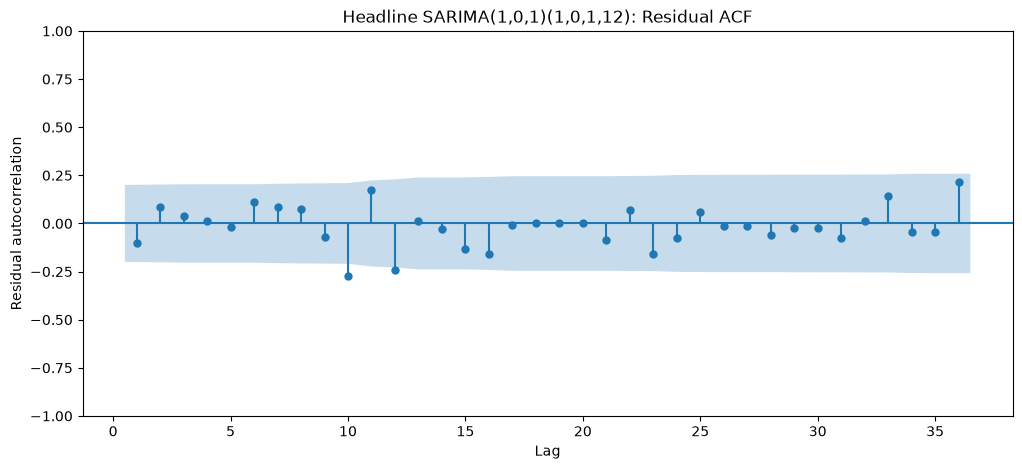

In [131]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf


headline_leader_key = (
    (1, 0, 1),
    (1, 0, 1, 12),
)

headline_leader = headline_fitted_models[
    headline_leader_key
]

headline_residuals = pd.Series(
    headline_leader.resid
).iloc[12:].dropna()

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    headline_residuals,
    lags=36,
    zero=False,
    ax=ax,
)

ax.set_title(
    "Headline SARIMA(1,0,1)(1,0,1,12): Residual ACF"
)
ax.set_xlabel("Lag")
ax.set_ylabel("Residual autocorrelation")

plt.show()

In [132]:
residual_autocorrelations = pd.Series(
    {
        lag: headline_residuals.autocorr(lag=lag)
        for lag in range(1, 37)
    },
    name="residual_autocorrelation",
)

residual_autocorrelations.reindex(
    residual_autocorrelations.abs()
    .sort_values(ascending=False)
    .index
).head(12)

36    0.389867
10   -0.295228
12   -0.259630
33    0.232973
23   -0.229864
16   -0.200133
11    0.188890
15   -0.163310
31   -0.120267
6     0.117172
21   -0.114048
24   -0.113471
Name: residual_autocorrelation, dtype: float64

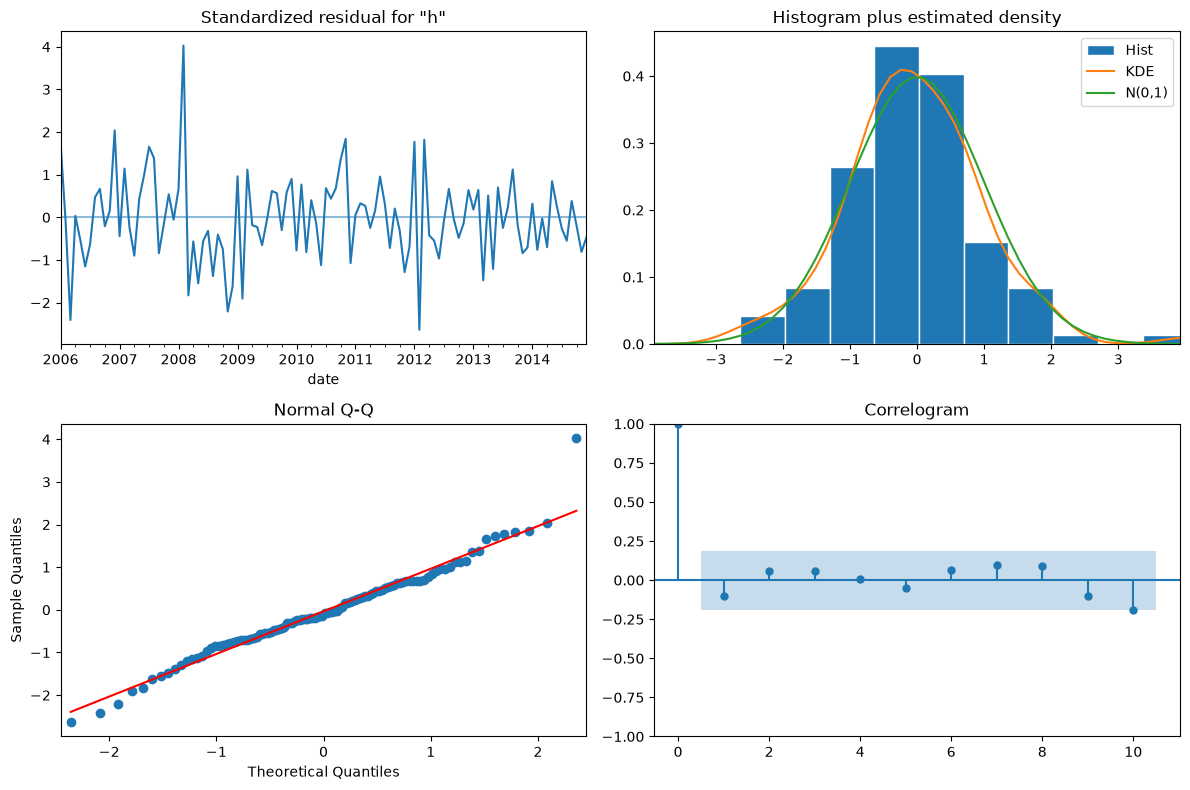

In [133]:
headline_leader.plot_diagnostics(
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

In [134]:
core_cv_candidates = [
    ((2, 0, 0), (1, 0, 1, 12)),
    ((1, 0, 1), (1, 0, 1, 12)),
    ((0, 0, 2), (1, 0, 1, 12)),
]

In [135]:
standardized_headline_residuals = pd.Series(
    headline_leader.filter_results.standardized_forecasts_error[0],
    index=headline.index,
).iloc[12:].dropna()

standardized_headline_residuals.reindex(
    standardized_headline_residuals.abs()
    .sort_values(ascending=False)
    .index
).head(10)

date
2008-02-01    4.028240
2012-02-01   -2.636434
2008-11-01   -2.207628
2009-02-01   -1.903953
2010-11-01    1.837290
2008-03-01   -1.828931
2012-03-01    1.818569
2012-01-01    1.771078
2007-07-01    1.656169
2008-12-01   -1.618117
dtype: float64

In [136]:
import warnings

import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX


# Narrow, predeclared D=1 search for headline inflation only.
headline_d1_candidates = [
    {
        "label": "ARMA(1,1) + seasonal MA(1)",
        "order": (1, 0, 1),
        "seasonal_order": (0, 1, 1, 12),
    },
    {
        "label": "AR(2) + seasonal MA(1)",
        "order": (2, 0, 0),
        "seasonal_order": (0, 1, 1, 12),
    },
    {
        "label": "AR(1) + seasonal MA(1)",
        "order": (1, 0, 0),
        "seasonal_order": (0, 1, 1, 12),
    },
    {
        "label": "ARMA(1,1) + seasonal AR(1)",
        "order": (1, 0, 1),
        "seasonal_order": (1, 1, 0, 12),
    },
]


def calculate_targeted_aicc(aic, nobs, parameter_count):
    """Calculate AICc for the targeted D=1 comparison."""
    denominator = nobs - parameter_count - 1

    if denominator <= 0:
        return np.nan

    correction = (
        2
        * parameter_count
        * (parameter_count + 1)
        / denominator
    )

    return aic + correction


def fit_and_diagnose_d1_candidate(
    series,
    label,
    order,
    seasonal_order,
):
    """Fit and diagnose one seasonally differenced headline model."""
    captured_messages = []

    try:
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter("always")

            model = SARIMAX(
                series,
                order=order,
                seasonal_order=seasonal_order,
                trend="n",
                enforce_stationarity=True,
                enforce_invertibility=True,
            )

            fitted = model.fit(
                disp=False,
                maxiter=500,
            )

            captured_messages = [
                str(item.message)
                for item in captured
            ]

        converged = bool(
            fitted.mle_retvals.get("converged", False)
        )

        finite_parameters = bool(
            np.isfinite(fitted.params).all()
        )

        parameter_count = len(fitted.params)
        nobs = int(fitted.nobs_effective)

        aicc = calculate_targeted_aicc(
            aic=fitted.aic,
            nobs=nobs,
            parameter_count=parameter_count,
        )

        residuals = pd.Series(fitted.resid).dropna()

        burn_in = max(
            int(getattr(fitted, "loglikelihood_burn", 0)),
            12,
        )

        residuals = residuals.iloc[burn_in:]

        p, _, q = order
        P, _, Q, _ = seasonal_order

        model_df = p + q + P + Q

        ljung_box = acorr_ljungbox(
            residuals,
            lags=[12, 24],
            model_df=model_df,
            return_df=True,
        )

        ar_roots = np.asarray(fitted.arroots)
        ma_roots = np.asarray(fitted.maroots)

        minimum_ar_root = (
            np.min(np.abs(ar_roots))
            if ar_roots.size > 0
            else np.nan
        )

        minimum_ma_root = (
            np.min(np.abs(ma_roots))
            if ma_roots.size > 0
            else np.nan
        )

        valid_fit = bool(
            converged
            and finite_parameters
            and np.isfinite(aicc)
            and np.isfinite(fitted.bic)
        )

        result = {
            "nobs_effective": nobs,
            "label": label,
            "order": order,
            "seasonal_order": seasonal_order,
            "parameters": parameter_count,
            "converged": converged,
            "valid_fit": valid_fit,
            "log_likelihood": fitted.llf,
            "aic": fitted.aic,
            "aicc": aicc,
            "bic": fitted.bic,
            "residual_mean": residuals.mean(),
            "residual_std": residuals.std(ddof=1),
            "ljung_box_p_12": (
                ljung_box.loc[12, "lb_pvalue"]
            ),
            "ljung_box_p_24": (
                ljung_box.loc[24, "lb_pvalue"]
            ),
            "minimum_ar_root_modulus": minimum_ar_root,
            "minimum_ma_root_modulus": minimum_ma_root,
            "warning_count": len(captured_messages),
            "warnings": " | ".join(captured_messages),
        }

        return result, fitted

    except Exception as error:
        result = {
            "label": label,
            "order": order,
            "seasonal_order": seasonal_order,
            "parameters": np.nan,
            "converged": False,
            "valid_fit": False,
            "log_likelihood": np.nan,
            "aic": np.nan,
            "aicc": np.nan,
            "bic": np.nan,
            "residual_mean": np.nan,
            "residual_std": np.nan,
            "ljung_box_p_12": np.nan,
            "ljung_box_p_24": np.nan,
            "minimum_ar_root_modulus": np.nan,
            "minimum_ma_root_modulus": np.nan,
            "warning_count": 1,
            "warnings": f"{type(error).__name__}: {error}",
        }

        return result, None


headline_d1_rows = []
headline_d1_fitted_models = {}

for candidate in headline_d1_candidates:
    result, fitted = fit_and_diagnose_d1_candidate(
        series=headline,
        label=candidate["label"],
        order=candidate["order"],
        seasonal_order=candidate["seasonal_order"],
    )

    headline_d1_rows.append(result)

    if fitted is not None:
        model_key = (
            candidate["order"],
            candidate["seasonal_order"],
        )

        headline_d1_fitted_models[model_key] = fitted


headline_d1_results = pd.DataFrame(
    headline_d1_rows
)

valid_mask = headline_d1_results["valid_fit"]

if valid_mask.any():
    headline_d1_results.loc[
        valid_mask,
        "delta_aicc_within_d1",
    ] = (
        headline_d1_results.loc[valid_mask, "aicc"]
        - headline_d1_results.loc[valid_mask, "aicc"].min()
    )

    headline_d1_results.loc[
        valid_mask,
        "delta_bic_within_d1",
    ] = (
        headline_d1_results.loc[valid_mask, "bic"]
        - headline_d1_results.loc[valid_mask, "bic"].min()
    )


headline_d1_results = headline_d1_results.sort_values(
    by=["valid_fit", "aicc", "bic"],
    ascending=[False, True, True],
    na_position="last",
).reset_index(drop=True)

headline_d1_results[
    [
        "label",
        "order",
        "seasonal_order",
        "parameters",
        "converged",
        "valid_fit",
        "aicc",
        "delta_aicc_within_d1",
        "bic",
        "delta_bic_within_d1",
        "residual_std",
        "ljung_box_p_12",
        "ljung_box_p_24",
        "minimum_ar_root_modulus",
        "minimum_ma_root_modulus",
        "warning_count",
    ]
]

,label,order,seasonal_order,parameters,converged,valid_fit,aicc,delta_aicc_within_d1,bic,delta_bic_within_d1,residual_std,ljung_box_p_12,ljung_box_p_24,minimum_ar_root_modulus,minimum_ma_root_modulus,warning_count
0,"ARMA(1,1) + seasonal MA(1)","(1, 0, 1)","(0, 1, 1, 12)",4,True,True,128.094400,0.000000,137.912232,0.000000,0.469227,0.006558,0.022607,1.154652,1.000179,2
1,AR(2) + seasonal MA(1),"(2, 0, 0)","(0, 1, 1, 12)",4,True,True,128.551575,0.457175,138.369407,0.457175,0.472879,0.002258,0.003396,1.739162,1.000266,0
2,AR(1) + seasonal MA(1),"(1, 0, 0)","(0, 1, 1, 12)",3,True,True,133.764542,5.670142,141.196717,3.284485,0.488581,0.000756,0.000087,7.246605,1.000240,0
3,"ARMA(1,1) + seasonal AR(1)","(1, 0, 1)","(1, 1, 0, 12)",4,True,True,156.729197,28.634797,166.547029,28.634797,0.527619,0.000957,0.000163,1.049729,1.482859,2


In [137]:
headline_d1_results[
    [
        "label",
        "converged",
        "warning_count",
        "warnings",
    ]
]

,label,converged,warning_count,warnings
0,"ARMA(1,1) + seasonal MA(1)",True,2,Non-stationary starting autoregressive paramet...
1,AR(2) + seasonal MA(1),True,0,
2,AR(1) + seasonal MA(1),True,0,
3,"ARMA(1,1) + seasonal AR(1)",True,2,Non-stationary starting autoregressive paramet...


In [138]:
headline_d0_comparison = headline_search[
    headline_search.apply(
        lambda row: (
            row["order"]
            in [
                (1, 0, 1),
                (2, 0, 0),
                (1, 0, 0),
            ]
            and row["seasonal_order"]
            == (1, 0, 1, 12)
        ),
        axis=1,
    )
][
    [
        "order",
        "seasonal_order",
        "parameters",
        "aicc",
        "bic",
    ]
].copy()

headline_d0_comparison["model_family"] = "D=0"


headline_d1_comparison = headline_d1_results.loc[
    headline_d1_results["valid_fit"],
    [
        "order",
        "seasonal_order",
        "parameters",
        "aicc",
        "bic",
    ],
].copy()

headline_d1_comparison["model_family"] = "D=1"


headline_information_criteria_comparison = pd.concat(
    [
        headline_d0_comparison,
        headline_d1_comparison,
    ],
    ignore_index=True,
)

headline_information_criteria_comparison = (
    headline_information_criteria_comparison
    .sort_values(["aicc", "bic"])
    .reset_index(drop=True)
)

headline_information_criteria_comparison

,order,seasonal_order,parameters,aicc,bic,model_family
0,"(1, 0, 1)","(0, 1, 1, 12)",4,128.094400,137.912232,D=1
1,"(2, 0, 0)","(0, 1, 1, 12)",4,128.551575,138.369407,D=1
2,"(1, 0, 0)","(0, 1, 1, 12)",3,133.764542,141.196717,D=1
3,"(1, 0, 1)","(1, 0, 1, 12)",6,147.389492,162.650596,D=0
4,"(2, 0, 0)","(1, 0, 1, 12)",6,147.720459,162.981563,D=0
5,"(1, 0, 0)","(1, 0, 1, 12)",5,150.896646,163.719067,D=0
6,"(1, 0, 1)","(1, 1, 0, 12)",4,156.729197,166.547029,D=1


In [139]:
headline_d1_results[
    [
        "label",
        "order",
        "seasonal_order",
        "aicc",
        "bic",
        "residual_std",
        "ljung_box_p_12",
        "ljung_box_p_24",
        "minimum_ar_root_modulus",
        "minimum_ma_root_modulus",
        "converged",
        "warning_count",
    ]
]

,label,order,seasonal_order,aicc,bic,residual_std,ljung_box_p_12,ljung_box_p_24,minimum_ar_root_modulus,minimum_ma_root_modulus,converged,warning_count
0,"ARMA(1,1) + seasonal MA(1)","(1, 0, 1)","(0, 1, 1, 12)",128.094400,137.912232,0.469227,0.006558,0.022607,1.154652,1.000179,True,2
1,AR(2) + seasonal MA(1),"(2, 0, 0)","(0, 1, 1, 12)",128.551575,138.369407,0.472879,0.002258,0.003396,1.739162,1.000266,True,0
2,AR(1) + seasonal MA(1),"(1, 0, 0)","(0, 1, 1, 12)",133.764542,141.196717,0.488581,0.000756,0.000087,7.246605,1.000240,True,0
3,"ARMA(1,1) + seasonal AR(1)","(1, 0, 1)","(1, 1, 0, 12)",156.729197,166.547029,0.527619,0.000957,0.000163,1.049729,1.482859,True,2


In [140]:
headline_d1_leaders = [
    ((1, 0, 1), (0, 1, 1, 12)),
    ((2, 0, 0), (0, 1, 1, 12)),
]

for key in headline_d1_leaders:
    fitted = headline_d1_fitted_models[key]

    print("\nMODEL:", key)
    display(model_parameter_table(fitted))

    print("AR roots:", fitted.arroots)
    print("MA roots:", fitted.maroots)

    if len(fitted.arroots) > 0:
        print(
            "Minimum AR-root modulus:",
            abs(fitted.arroots).min(),
        )

    if len(fitted.maroots) > 0:
        print(
            "Minimum MA-root modulus:",
            abs(fitted.maroots).min(),
        )


MODEL: ((1, 0, 1), (0, 1, 1, 12))


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
ar.L1,0.866062,0.175093,4.946282,7.564426e-07,0.522885,1.209238
ma.L1,-0.697490,0.211593,-3.296381,9.793901e-04,-1.112204,-0.282776
ma.S.L12,-0.997858,18.815637,-0.053033,9.577053e-01,-37.875828,35.880113
sigma2,0.155250,2.911208,0.053328,9.574703e-01,-5.550614,5.861114


AR roots: [1.15465225]
MA roots: [-1.00017874e+00-0.j         -8.66180196e-01-0.50008937j
 -8.66180196e-01+0.50008937j -5.00089370e-01-0.8661802j
 -5.00089370e-01+0.8661802j  -2.16107502e-17-1.00017874j
 -2.16107502e-17+1.00017874j  5.00089370e-01-0.8661802j
  5.00089370e-01+0.8661802j   8.66180196e-01-0.50008937j
  8.66180196e-01+0.50008937j  1.00017874e+00-0.j
  1.43371187e+00-0.j        ]
Minimum AR-root modulus: 1.1546522470377705
Minimum MA-root modulus: 1.0001787391861812

MODEL: ((2, 0, 0), (0, 1, 1, 12))


,estimate,standard_error,z_statistic,p_value,ci_lower,ci_upper
ar.L1,0.099487,0.090341,1.101237,0.270793,-0.077578,0.276553
ar.L2,0.273409,0.102927,2.656349,0.007899,0.071677,0.475142
ma.S.L12,-0.996810,13.795646,-0.072255,0.942399,-28.035778,26.042159
sigma2,0.155686,2.140845,0.072722,0.942028,-4.040293,4.351664


AR roots: [ 1.73916159 -2.103038  ]
MA roots: [-1.00026633e+00-0.j         -8.66256051e-01-0.50013316j
 -8.66256051e-01+0.50013316j -5.00133164e-01-0.86625605j
 -5.00133164e-01+0.86625605j -2.14132188e-16-1.00026633j
 -2.14132188e-16+1.00026633j  5.00133164e-01-0.86625605j
  5.00133164e-01+0.86625605j  1.00026633e+00-0.j
  8.66256051e-01-0.50013316j  8.66256051e-01+0.50013316j]
Minimum AR-root modulus: 1.7391615865597994
Minimum MA-root modulus: 1.0002663286186801


In [141]:
from src.data.load_cny_calendar import load_cny_calendar


CNY_CALENDAR_PATH = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "chinese_new_year_dates.csv"
)

cny_calendar = load_cny_calendar(
    CNY_CALENDAR_PATH,
    start_year=2006,
    end_year=2030,
)

cny_calendar

,year,cny_date
0,2006,2006-01-29
1,2007,2007-02-18
2,2008,2008-02-07
3,2009,2009-01-26
4,2010,2010-02-14
5,2011,2011-02-03
6,2012,2012-01-23
7,2013,2013-02-10
8,2014,2014-01-31
9,2015,2015-02-19


In [142]:
cny_development = cny_calendar.loc[
    cny_calendar["year"].between(2006, 2014)
].copy()

cny_development

,year,cny_date
0,2006,2006-01-29
1,2007,2007-02-18
2,2008,2008-02-07
3,2009,2009-01-26
4,2010,2010-02-14
5,2011,2011-02-03
6,2012,2012-01-23
7,2013,2013-02-10
8,2014,2014-01-31


In [143]:
cny_development.assign(
    month=cny_development["cny_date"].dt.month,
    day=cny_development["cny_date"].dt.day,
)

,year,cny_date,month,day
0,2006,2006-01-29,1,29
1,2007,2007-02-18,2,18
2,2008,2008-02-07,2,7
3,2009,2009-01-26,1,26
4,2010,2010-02-14,2,14
5,2011,2011-02-03,2,3
6,2012,2012-01-23,1,23
7,2013,2013-02-10,2,10
8,2014,2014-01-31,1,31


In [144]:
from src.features.cny_regressors import (
    build_cny_regressors,
)


cny_regressor_result = build_cny_regressors(
    cny_calendar=cny_calendar,
    start_date=DEVELOPMENT_START,
    end_date=DEVELOPMENT_END,
)

cny_regressors = cny_regressor_result.monthly
cny_audit = cny_regressor_result.audit

cny_regressors.loc[
    (
        cny_regressors["cny_pressure"] > 0
    )
    | (
        cny_regressors["cny_normalisation"] > 0
    )
]

,cny_pressure,cny_normalisation
date,,
2006-01-01,0.586207,0.000000
2006-02-01,0.413793,1.000000
2007-02-01,0.862069,0.000000
2007-03-01,0.137931,1.000000
2008-01-01,0.275862,0.000000
2008-02-01,0.724138,0.571429
2008-03-01,0.000000,0.428571
2009-01-01,0.689655,0.000000
2009-02-01,0.310345,1.000000


In [145]:
cny_audit.loc[
    cny_audit["cny_year"].between(2006, 2014),
    [
        "cny_year",
        "phase",
        "month",
        "affected_days",
        "total_phase_days",
        "fraction",
    ],
]

,cny_year,phase,month,affected_days,total_phase_days,fraction
0,2006,pressure,2006-01-01,17,29,0.586207
1,2006,pressure,2006-02-01,12,29,0.413793
2,2006,normalisation,2006-02-01,14,14,1.000000
3,2007,pressure,2007-02-01,25,29,0.862069
4,2007,pressure,2007-03-01,4,29,0.137931
5,2007,normalisation,2007-03-01,14,14,1.000000
6,2008,pressure,2008-01-01,8,29,0.275862
7,2008,pressure,2008-02-01,21,29,0.724138
8,2008,normalisation,2008-02-01,8,14,0.571429
9,2008,normalisation,2008-03-01,6,14,0.428571


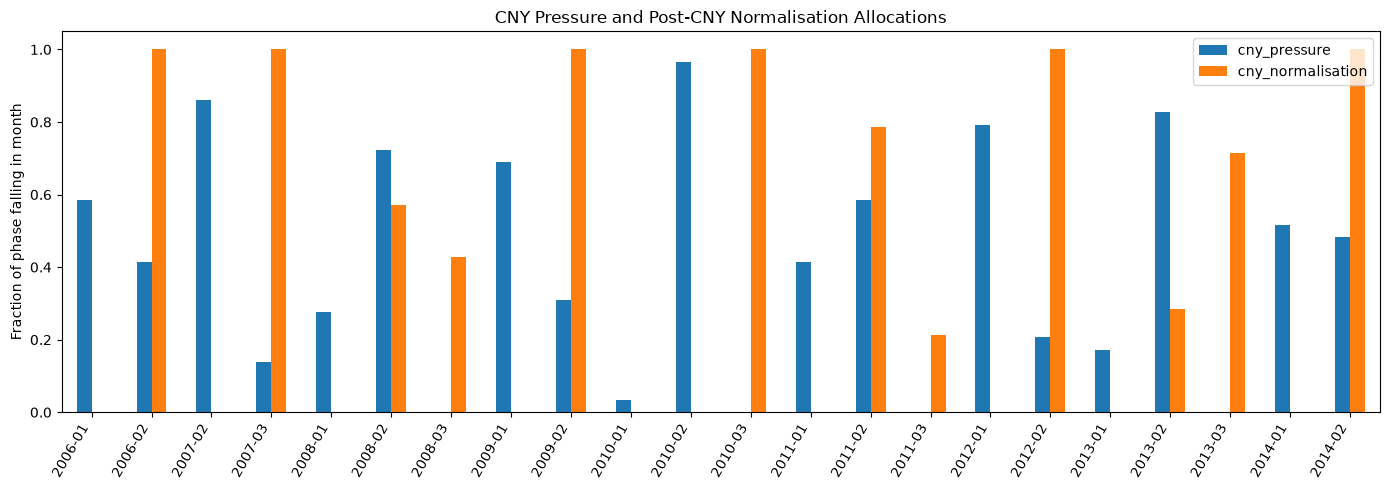

In [149]:
affected_cny_months = cny_regressors.loc[
    cny_regressors.sum(axis=1) > 0
].copy()

plot_data = affected_cny_months.copy()

plot_data.index = plot_data.index.strftime("%Y-%m")

ax = plot_data.plot(
    kind="bar",
    figsize=(14, 5),
    title="CNY Pressure and Post-CNY Normalisation Allocations",
)

ax.set_xlabel("")
ax.set_ylabel("Fraction of phase falling in month")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()